#Google drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


#import

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib as mpl
from matplotlib.font_manager import FontProperties
import warnings
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import os

#Emotion

In [ ]:
companies = [
    "SamsungBiologics",
    "Naver",
    "Skhynix",
    "PoscoHoldings",
    "Kia",
    "Lgchem",
    "Kbfg",
    "Samsung",
    "Hyundai",
    "Lgensol"
]

In [ ]:
folder_path = "/content/drive/MyDrive/share_drive/박박박사/백테스팅/감성분석 - 공휴일 처리후 4로 나눈 값"

dataframes = {}

In [ ]:
for company in companies:
    df_name = f"df_{company}"
    file_name = f"{company}_sentiment_result_sum_holiday_processed.csv"
    file_path = os.path.join(folder_path, file_name)

    try:
        df = pd.read_csv(file_path)

        df.rename(columns={'긍정 확률 (1)': '긍정', '부정 확률 (0)': '부정', '일자':'날짜'}, inplace=True)
        df['날짜'] = pd.to_datetime(df['날짜'], format='%Y%m%d')

        df['total_prob'] = df['긍정'] + df['부정']

        df['total_prob'] = df['total_prob'].apply(lambda x: x if x != 0 else 1)
        df['긍정'] = df['긍정'] / df['total_prob']
        df['부정'] = df['부정'] / df['total_prob']


        df.drop(columns=['total_prob','요일','휴장일여부','그룹_요일_요약'], inplace=True)

        df['감정'] = 0

        df.loc[df['긍정'] > df['부정'], '감정'] = 1

        dataframes[df_name] = df
        print(df.head())
    except FileNotFoundError:
        print(f"오류: '{file_name}' 파일을 찾을 수 없습니다.")


          날짜        부정        긍정  감정
0 2025-01-02  0.679667  0.320333   0
1 2025-01-03  0.280071  0.719929   1
2 2025-01-06  0.226636  0.773364   1
3 2025-01-07  0.385051  0.614949   1
4 2025-01-08  0.459795  0.540205   1
          날짜        부정        긍정  감정
0 2025-01-02  0.394612  0.605388   1
1 2025-01-03  0.258845  0.741155   1
2 2025-01-06  0.151652  0.848348   1
3 2025-01-07  0.312328  0.687672   1
4 2025-01-08  0.228564  0.771436   1
          날짜        부정        긍정  감정
0 2025-01-02  0.653211  0.346789   0
1 2025-01-03  0.441472  0.558528   1
2 2025-01-06  0.068685  0.931315   1
3 2025-01-07  0.278624  0.721376   1
4 2025-01-08  0.436703  0.563297   1
          날짜        부정        긍정  감정
0 2025-01-02  0.482539  0.517461   1
1 2025-01-03  0.548685  0.451315   0
2 2025-01-06  0.465481  0.534519   1
3 2025-01-07  0.595808  0.404192   0
4 2025-01-08  0.454286  0.545714   1
          날짜        부정        긍정  감정
0 2025-01-02  0.338922  0.661078   1
1 2025-01-03  0.060278  0.939722   1
2

#Stocking price

In [ ]:
companies_2 = [
    "삼성바이오로직스주가", "NAVER주가", "삼성전자주가",
    "sk하이닉스주가", "POSCO홀딩스주가", "LG에너지솔루션주가",
    "현대차주가", "기아주가", "LG화학주가", "KB금융주가"
]

In [ ]:
folder_path_stock_price = "/content/drive/MyDrive/share_drive/박박박사/백테스팅/주가"

df_stock_price_dict = {}

In [ ]:
def convert_volume(value):
    if isinstance(value, str):
        if 'M' in value:
            return float(value.replace('M', '')) * 1000000
        elif 'K' in value:
            return float(value.replace('K', '')) * 1000
    return value

for company in companies_2:
    file_name = f"{company}.csv"
    file_path = os.path.join(folder_path_stock_price, file_name)
    try:
        df = pd.read_csv(file_path)
        df['날짜'] = pd.to_datetime(df['날짜'])

        if '거래량' in df.columns:
            df['거래량'] = df['거래량'].apply(convert_volume)

        df = df.drop(columns=["시가", "고가", "저가"])
        df = df.rename(columns={"변동 %": "변동성"})
        df = df.sort_values(by='날짜', ascending=True).reset_index(drop=True)

        df_stock_price_dict[company] = df
        df['변동성'] = df['변동성'].str.replace('%', '')
        print(df.head())
    except FileNotFoundError:
        print(f"오류: '{file_name}' 파일을 찾을 수 없습니다.")

          날짜         종가       거래량    변동성
0 2025-01-02    934,000   54670.0  -1.58
1 2025-01-03    940,000   43970.0   0.64
2 2025-01-06    946,000   44660.0   0.64
3 2025-01-07    983,000  151400.0   3.91
4 2025-01-08  1,008,000  106870.0   2.54
          날짜       종가       거래량    변동성
0 2025-01-02  193,800  694970.0  -2.56
1 2025-01-03  200,500  794250.0   3.46
2 2025-01-06  208,500  764780.0   3.99
3 2025-01-07  208,000  601660.0  -0.24
4 2025-01-08  207,000  520260.0  -0.48
          날짜      종가         거래량    변동성
0 2025-01-02  53,400  16550000.0   0.38
1 2025-01-03  54,400  19130000.0   1.87
2 2025-01-06  55,900  18880000.0   2.76
3 2025-01-07  55,400  16950000.0  -0.89
4 2025-01-08  57,300  26220000.0   3.43
          날짜       종가        거래량    변동성
0 2025-01-02  171,200  2080000.0  -1.55
1 2025-01-03  181,900  4220000.0   6.25
2 2025-01-06  199,800  7260000.0   9.84
3 2025-01-07  195,000  6020000.0  -2.40
4 2025-01-08  194,700  4230000.0  -0.15
          날짜       종가       거래량    변동성
0

#Merge

In [ ]:
result_path = "/content/drive/MyDrive/share_drive/박박박사/백테스팅/result_Date"

In [ ]:
company_name_map = {
    "SamsungBiologics": "삼성바이오로직스주가",
    "Naver": "NAVER주가",
    "Skhynix": "sk하이닉스주가",
    "PoscoHoldings": "POSCO홀딩스주가",
    "Kia": "기아주가",
    "Lgchem": "LG화학주가",
    "Kbfg": "KB금융주가",
    "Samsung": "삼성전자주가",
    "Hyundai": "현대차주가",
    "Lgensol": "LG에너지솔루션주가"
}

merged_dataframes = {}

In [ ]:
for company in companies:
    sentiment_df_key = f"df_{company}"

    stock_price_key = company_name_map.get(company)

    if sentiment_df_key in dataframes and stock_price_key and stock_price_key in df_stock_price_dict:
        df_sentiment = dataframes[sentiment_df_key]
        df_stock_price = df_stock_price_dict[stock_price_key]

        try:
            merged_df = pd.merge(df_sentiment, df_stock_price, on='날짜', how='left')

            merged_dataframes[company] = merged_df

            merged_df = merged_df.rename(columns={'날짜': 'date', '부정': 'neg','긍정': 'pos','감정': 'emotion','종가':'closing_price','거래량': 'trading','변동성': 'changing'})

            merged_df['calculation'] = merged_df['pos'] - merged_df['neg']

            merged_dataframes[company] = merged_df
            print(f"'{company}' 데이터프레임 병합 완료.")
            print(merged_df.head())

        except Exception as e:
            print(f"'{company}' 데이터프레임 병합 중 오류 발생: {e}")

'SamsungBiologics' 데이터프레임 병합 완료.
        date       neg       pos  emotion closing_price   trading changing  \
0 2025-01-02  0.679667  0.320333        0       934,000   54670.0    -1.58   
1 2025-01-03  0.280071  0.719929        1       940,000   43970.0     0.64   
2 2025-01-06  0.226636  0.773364        1       946,000   44660.0     0.64   
3 2025-01-07  0.385051  0.614949        1       983,000  151400.0     3.91   
4 2025-01-08  0.459795  0.540205        1     1,008,000  106870.0     2.54   

   calculation  
0    -0.359333  
1     0.439857  
2     0.546727  
3     0.229897  
4     0.080410  
'Naver' 데이터프레임 병합 완료.
        date       neg       pos  emotion closing_price   trading changing  \
0 2025-01-02  0.394612  0.605388        1       193,800  694970.0    -2.56   
1 2025-01-03  0.258845  0.741155        1       200,500  794250.0     3.46   
2 2025-01-06  0.151652  0.848348        1       208,500  764780.0     3.99   
3 2025-01-07  0.312328  0.687672        1       208,000  60166

In [ ]:
output_folder = "/content/drive/MyDrive/share_drive/박박박사/백테스팅/result_Date"

for company, df in merged_dataframes.items():
    file_name = f"df_{company}.csv"
    file_path = os.path.join(output_folder, file_name)
    df.to_csv(file_path, index=False, encoding='utf-8-sig')


#backtesting

In [ ]:
# import matplotlib.pyplot as plt
# import matplotlib.ticker as ticker
# import matplotlib as mpl
# from matplotlib.font_manager import FontProperties
# import warnings

--- Starting Backtest for Each Company ---
✅ 'SamsungBiologics' Backtest Complete.
   Final Capital: 10,968,723 KRW
   Final Return: 9.69%
------------------------------


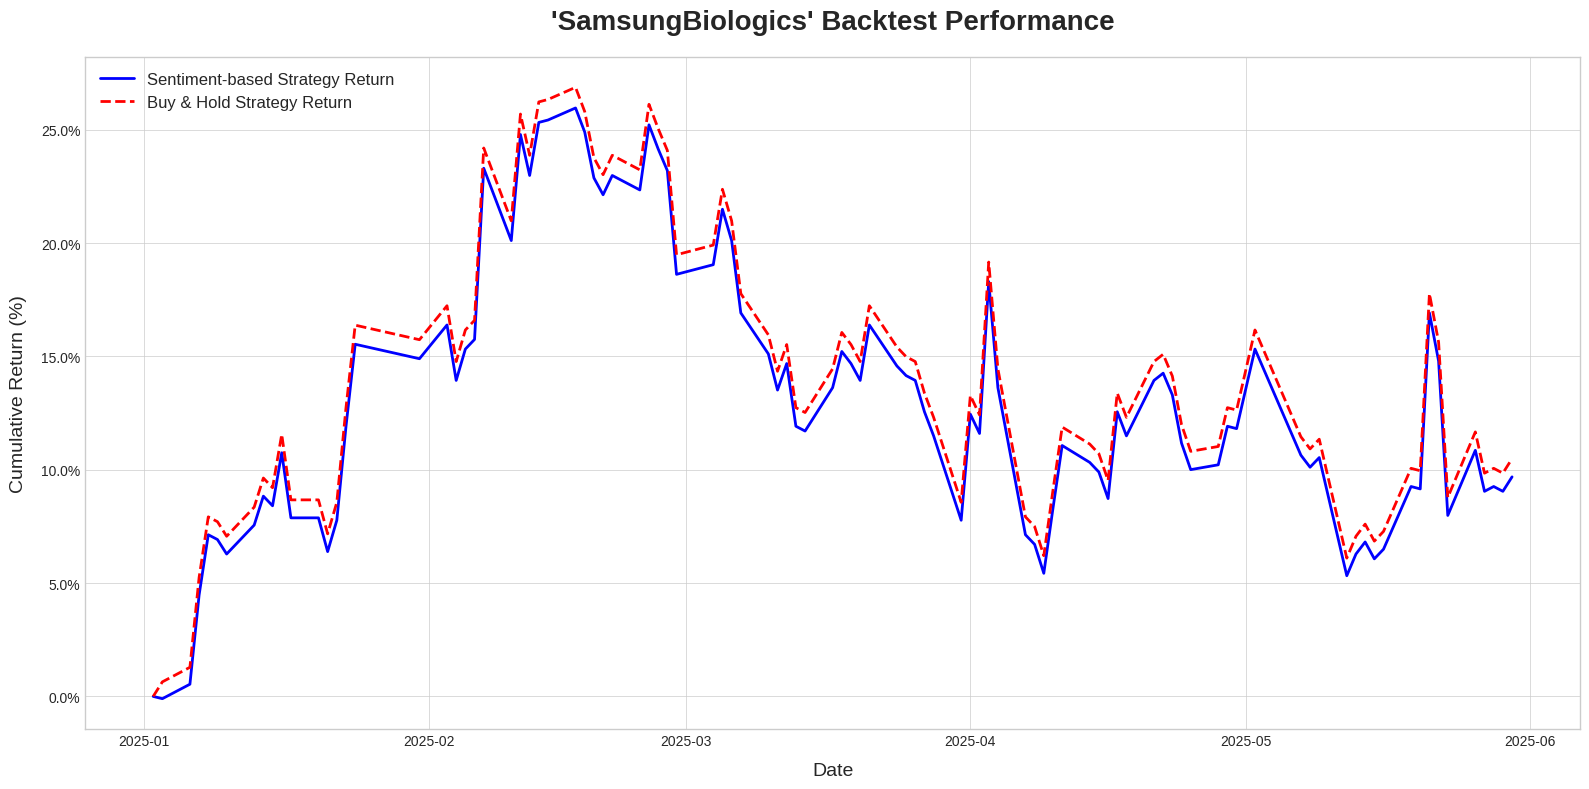

✅ 'Naver' Backtest Complete.
   Final Capital: 9,341,621 KRW
   Final Return: -6.58%
------------------------------


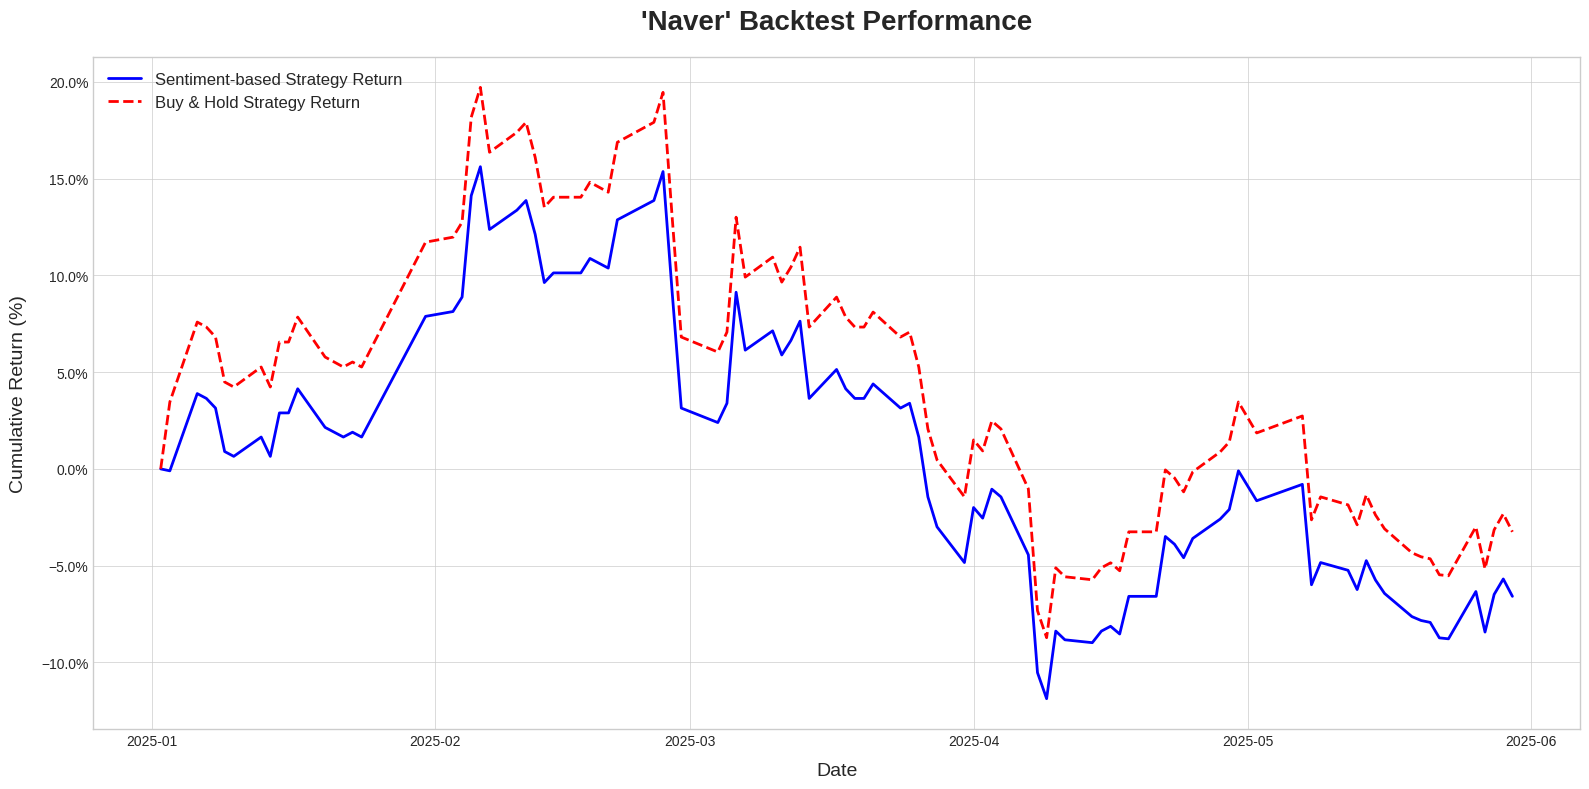

✅ 'Skhynix' Backtest Complete.
   Final Capital: 11,232,441 KRW
   Final Return: 12.32%
------------------------------


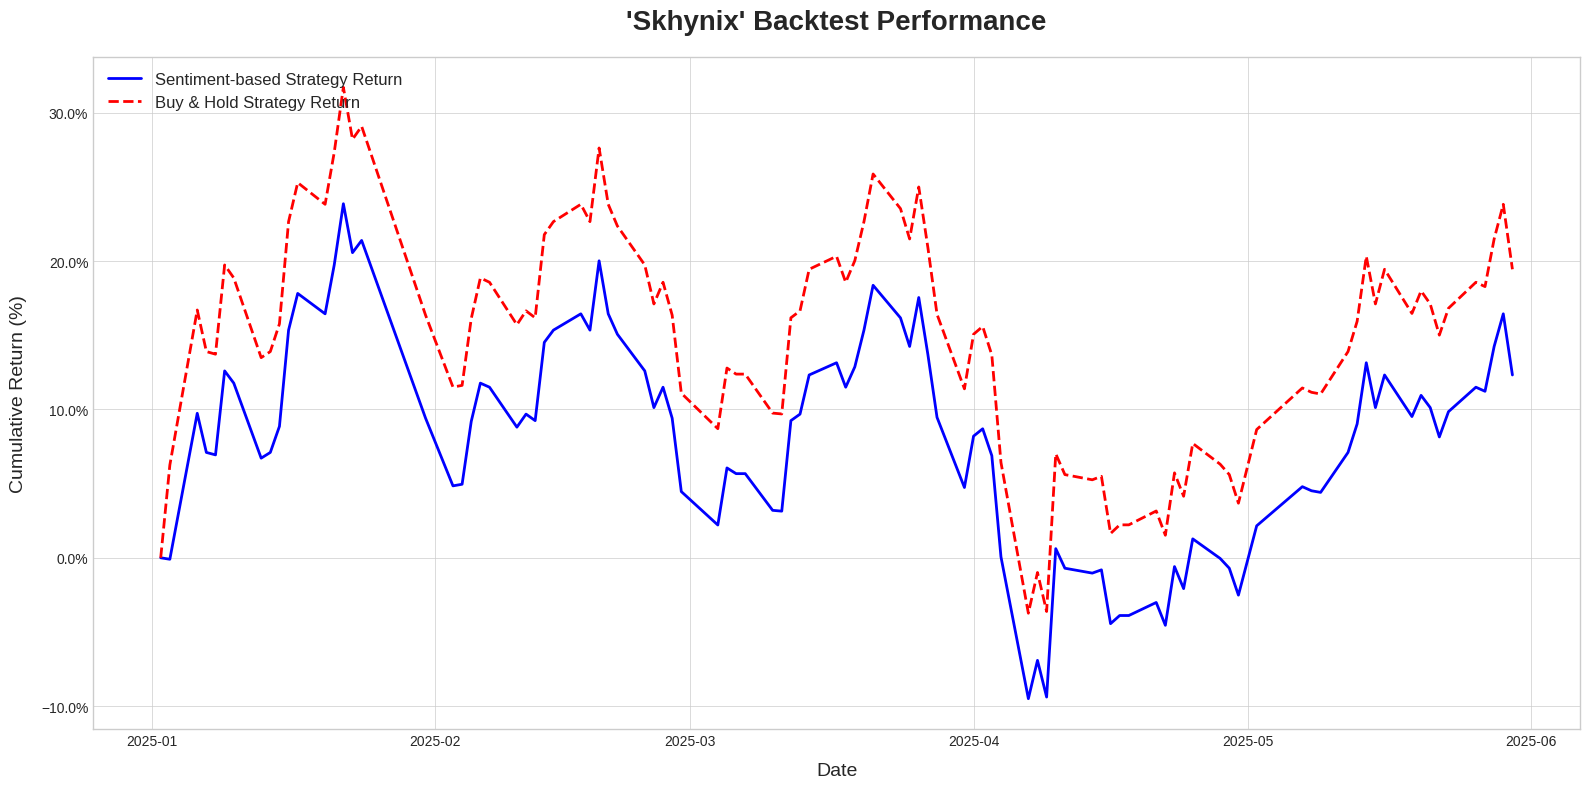

✅ 'PoscoHoldings' Backtest Complete.
   Final Capital: 9,531,985 KRW
   Final Return: -4.68%
------------------------------


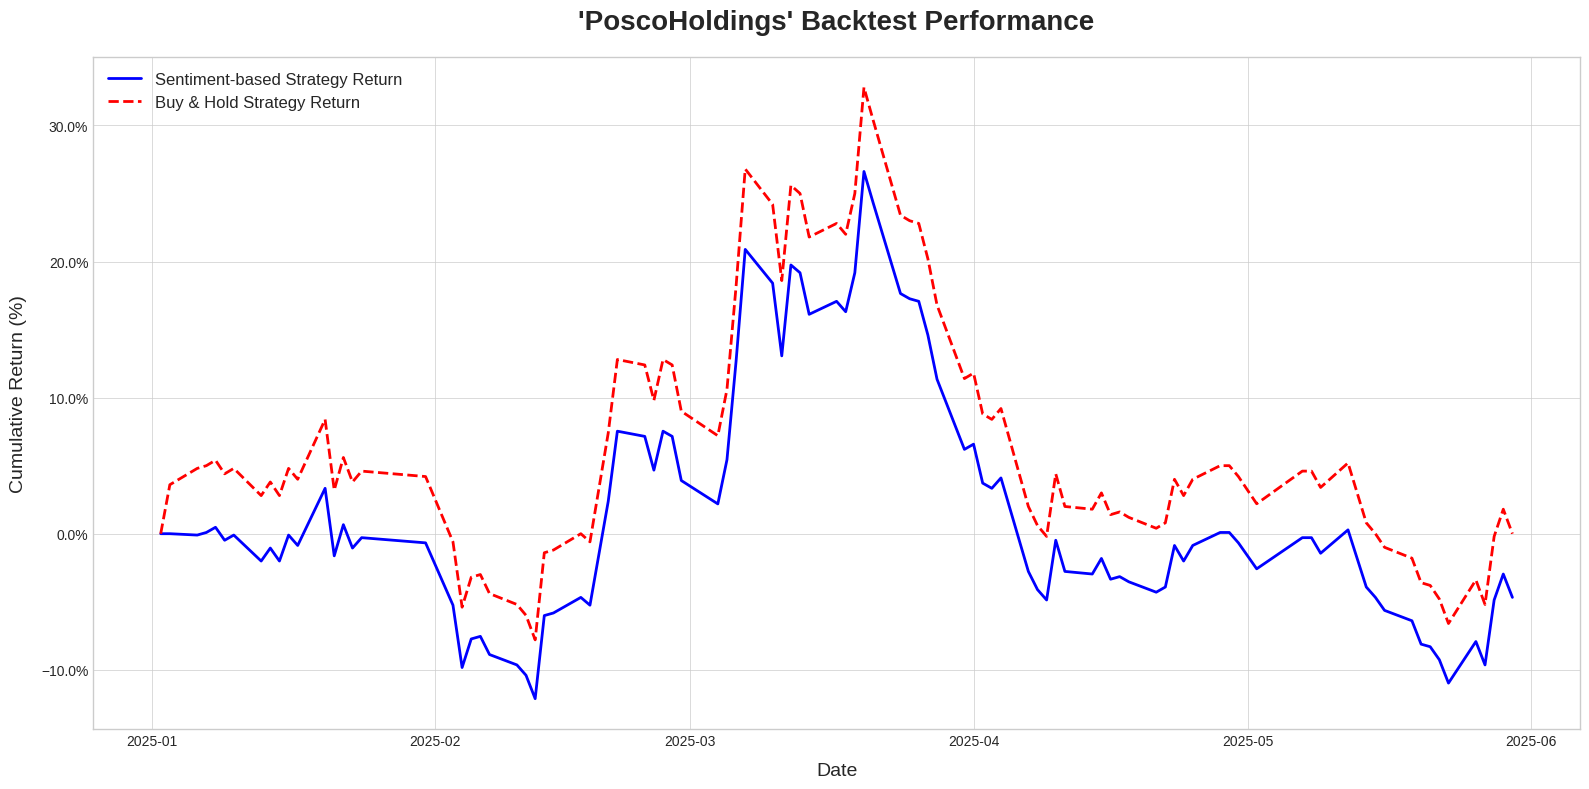

✅ 'Kia' Backtest Complete.
   Final Capital: 8,867,855 KRW
   Final Return: -11.32%
------------------------------


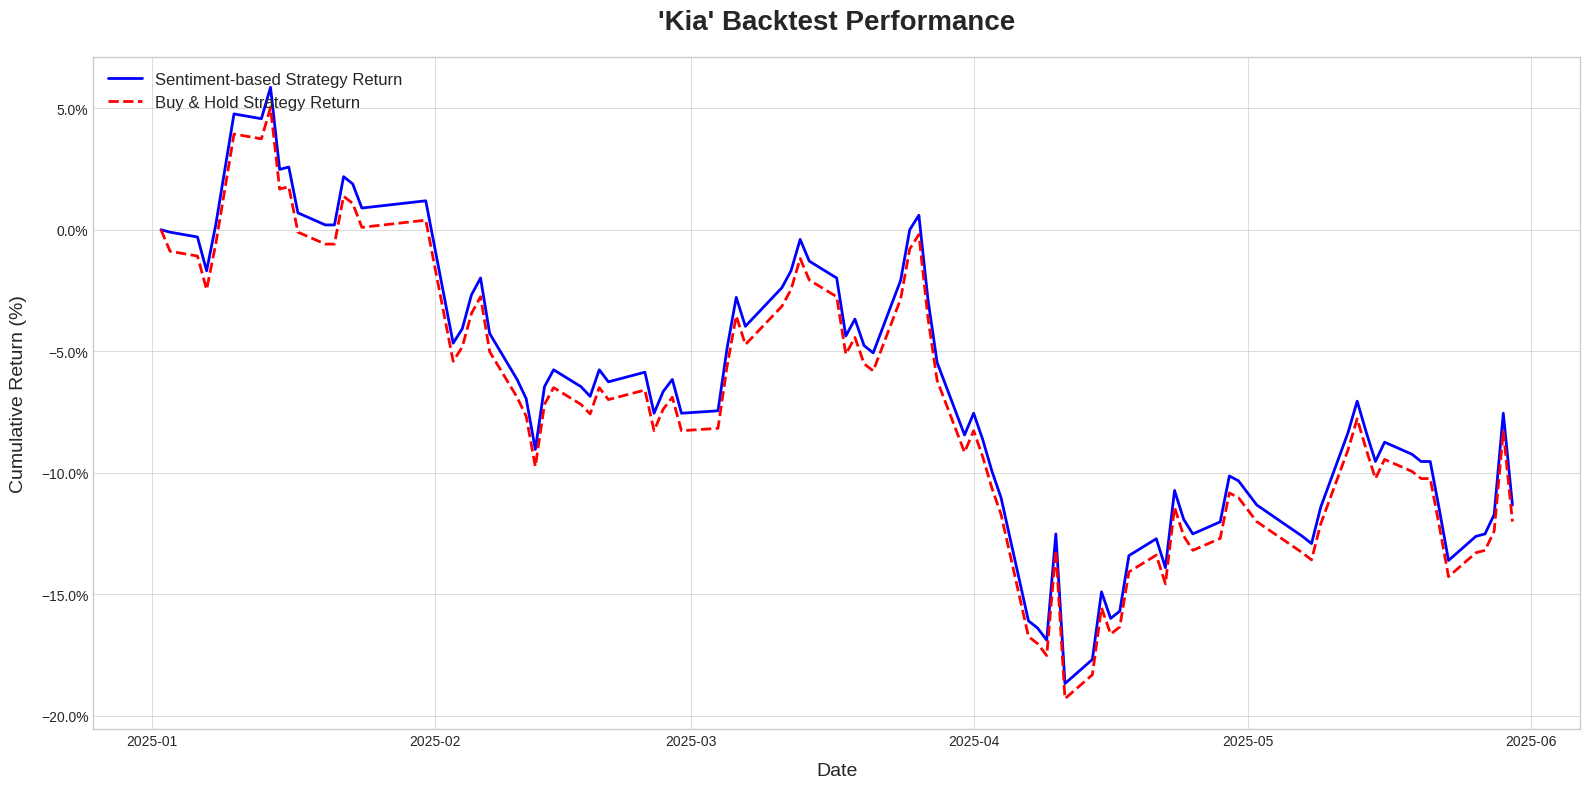

✅ 'Lgchem' Backtest Complete.
   Final Capital: 7,773,037 KRW
   Final Return: -22.27%
------------------------------


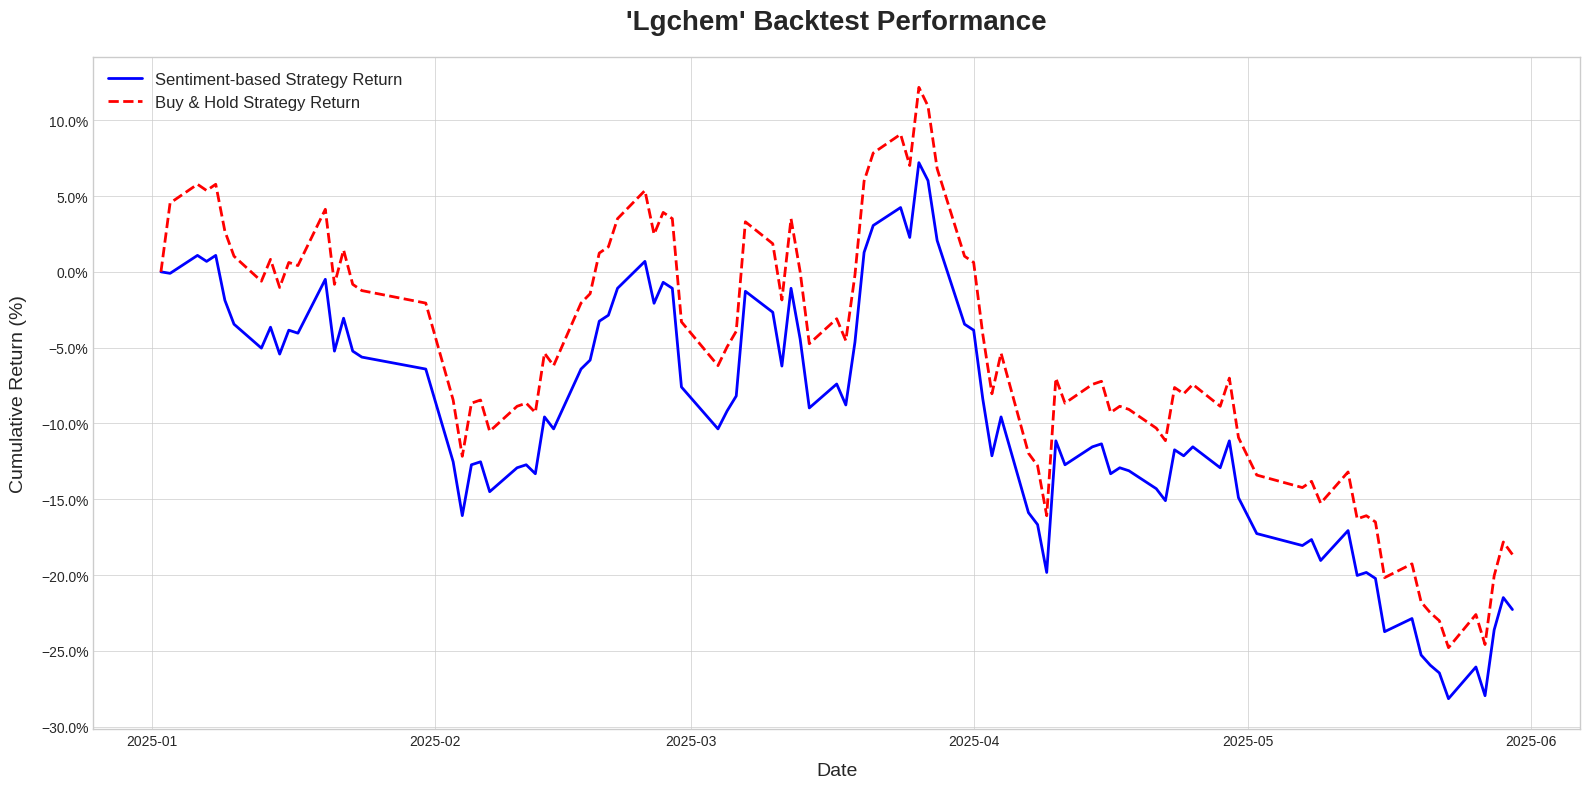

✅ 'Kbfg' Backtest Complete.
   Final Capital: 12,436,301 KRW
   Final Return: 24.36%
------------------------------


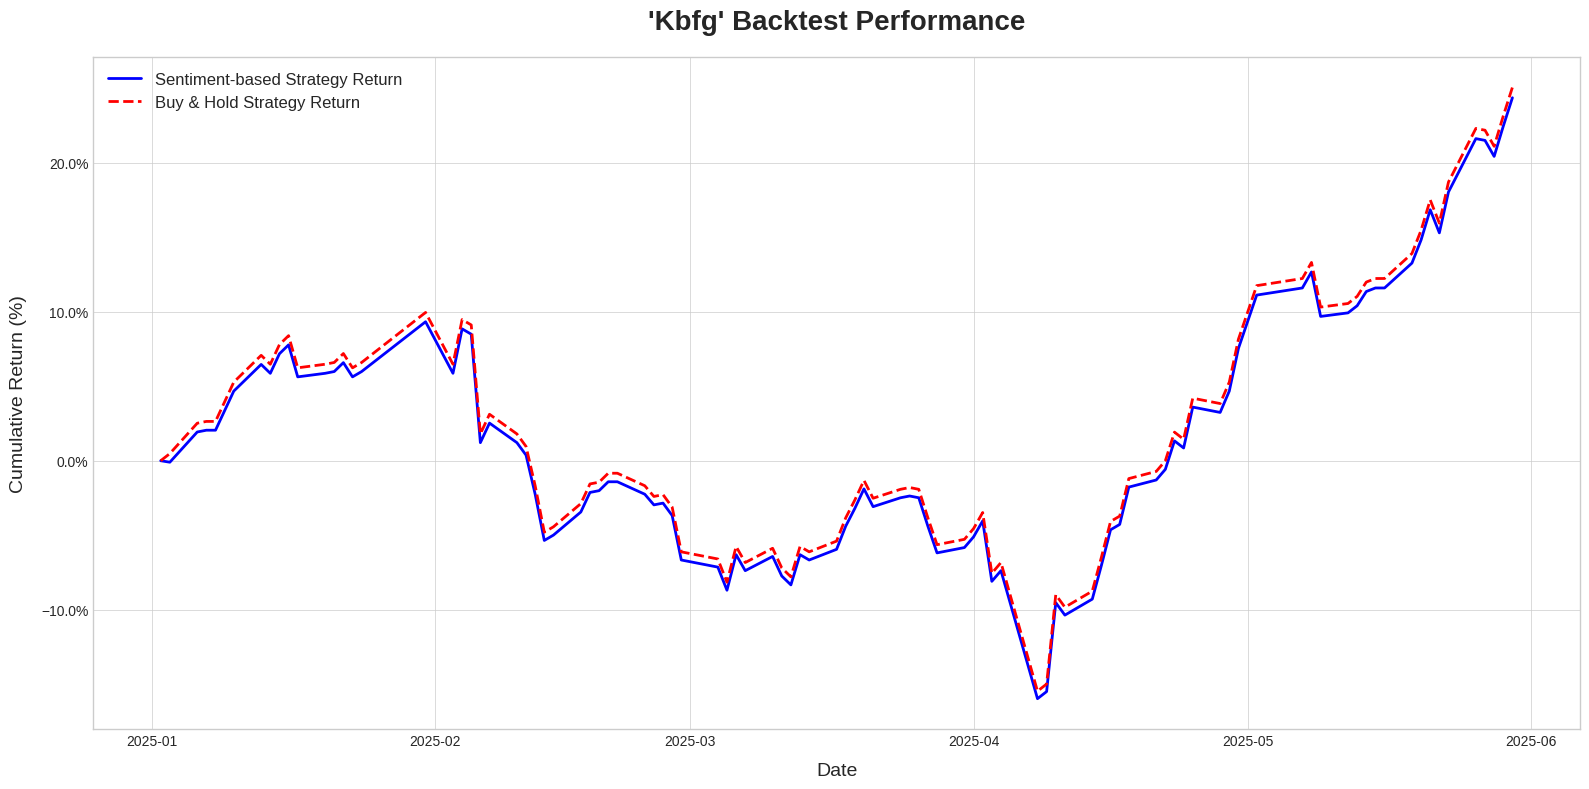

✅ 'Samsung' Backtest Complete.
   Final Capital: 10,320,882 KRW
   Final Return: 3.21%
------------------------------


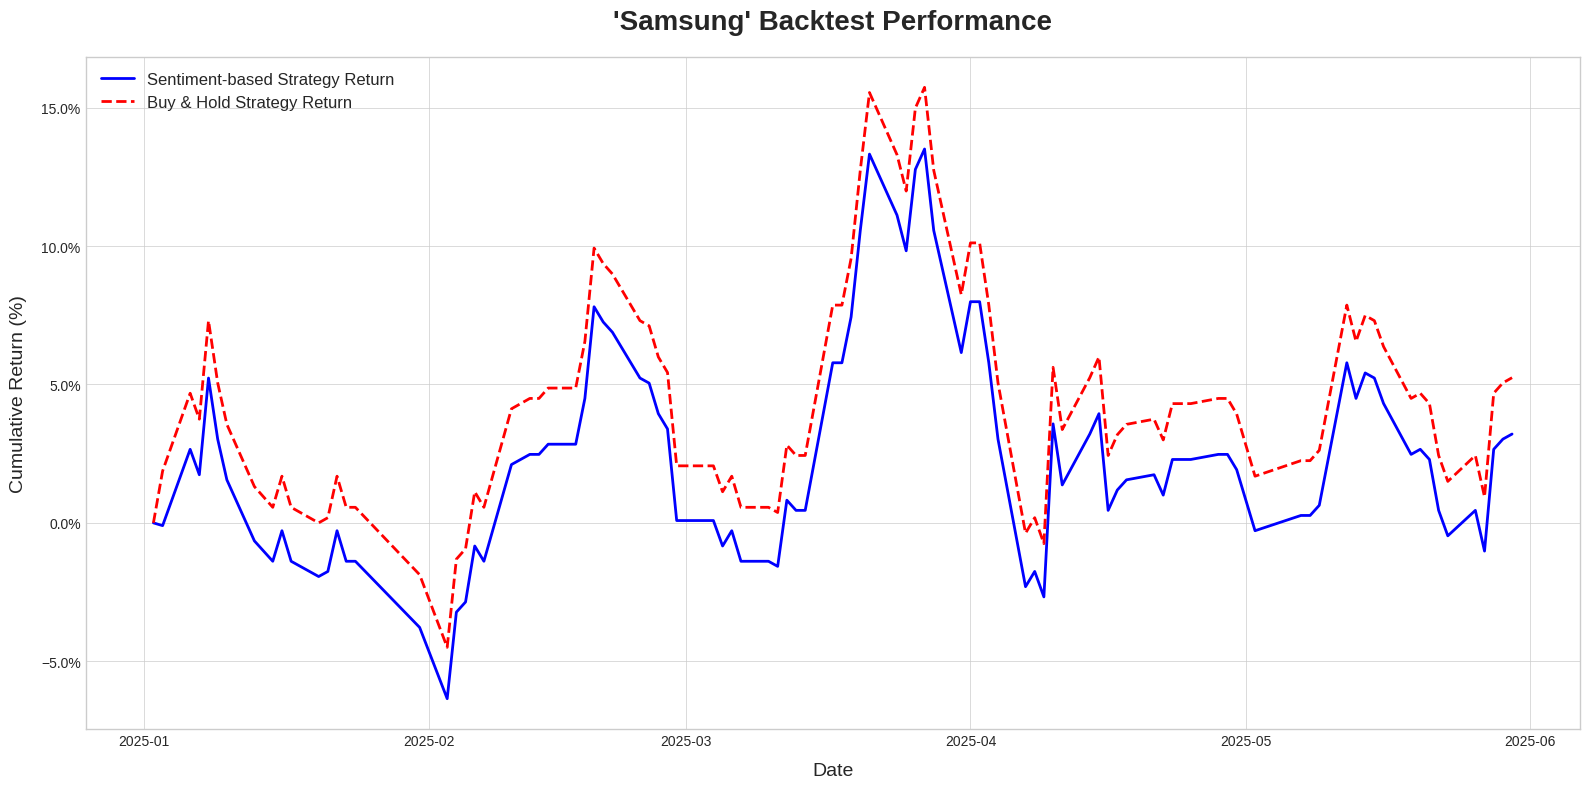

✅ 'Hyundai' Backtest Complete.
   Final Capital: 8,689,531 KRW
   Final Return: -13.10%
------------------------------


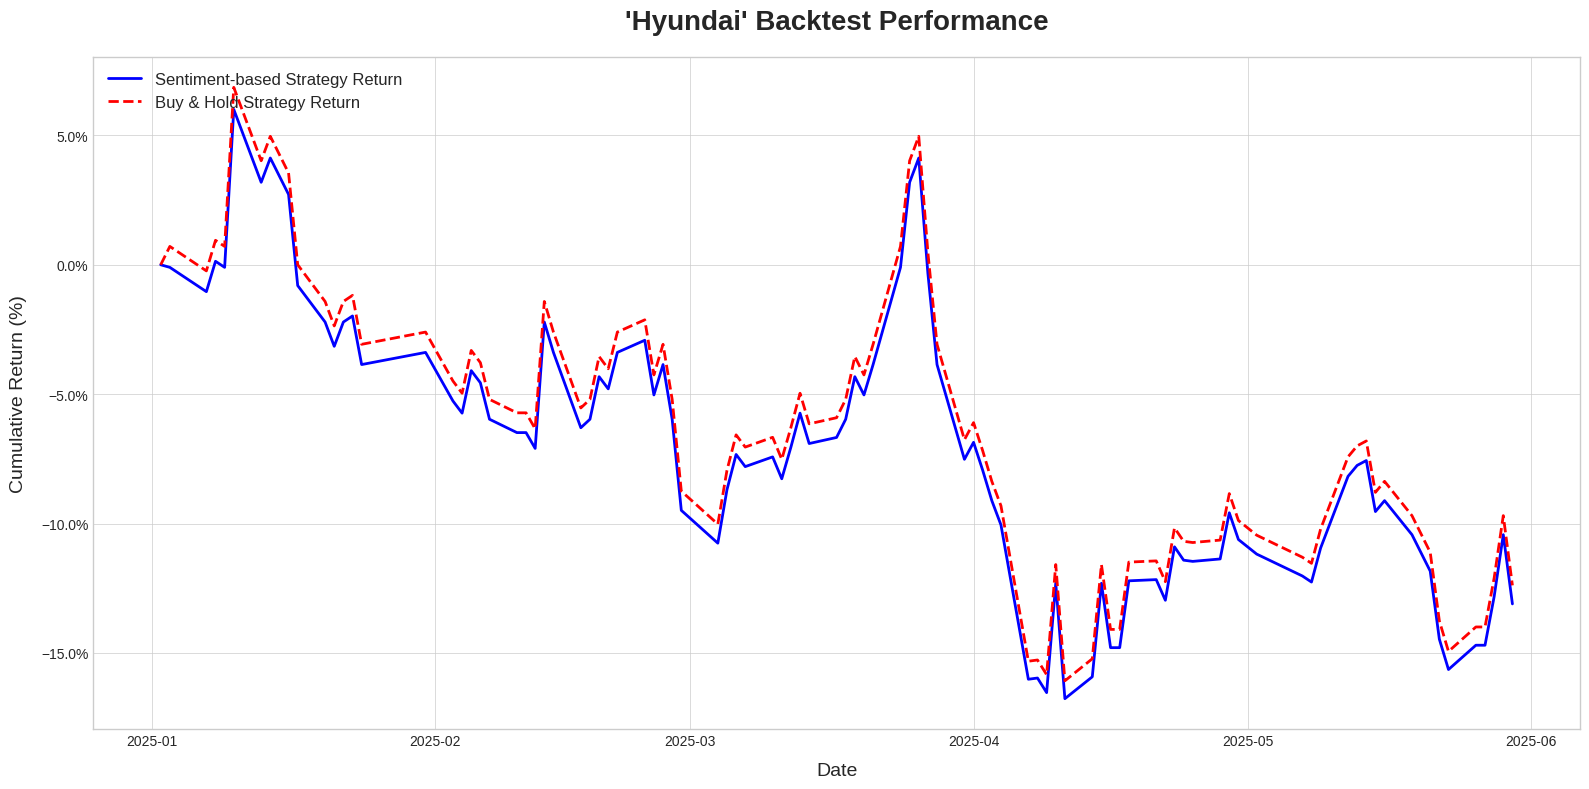

✅ 'Lgensol' Backtest Complete.
   Final Capital: 8,023,708 KRW
   Final Return: -19.76%
------------------------------


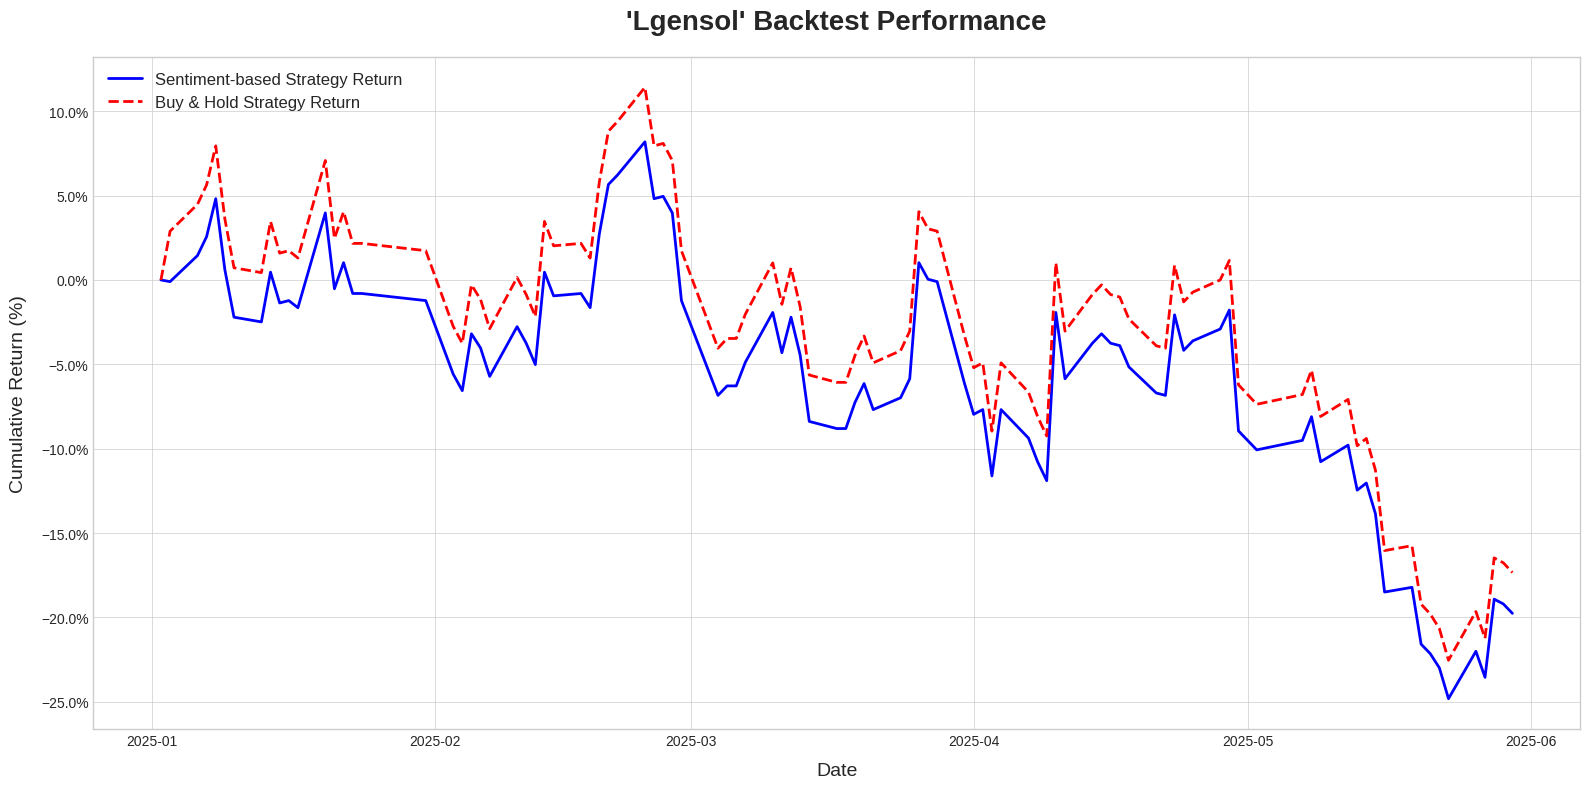

In [ ]:
# def run_backtest(df, initial_capital=10000000, fee_rate=0.001):
#     backtest_df = df.copy()
#     capital = float(initial_capital)
#     shares = 0
#     position = 0  # 0: 현금, 1: 주식 보유

#     backtest_df['capital'] = np.nan
#     backtest_df['return_rate'] = np.nan
#     backtest_df['position'] = ''

#     backtest_df.loc[backtest_df.index[0], 'capital'] = capital
#     backtest_df.loc[backtest_df.index[0], 'return_rate'] = 0.0
#     backtest_df.loc[backtest_df.index[0], 'position'] = 'observation'

#     for i in range(1, len(backtest_df)):
#         sentiment = backtest_df.loc[backtest_df.index[i], 'emotion']
#         current_price = backtest_df.loc[backtest_df.index[i], 'closing_price']

#         # 매수 조건 (긍정일 때)
#         if sentiment == 1 and position == 0:
#             shares = capital / current_price
#             capital = 0
#             capital -= shares * current_price * fee_rate
#             position = 1
#             backtest_df.loc[backtest_df.index[i], 'position'] = 'buy'

#         # 매도 조건 (부정일 때)
#         elif sentiment == -1 and position == 1:
#             capital = shares * current_price
#             shares = 0
#             capital -= capital * fee_rate
#             position = 0
#             backtest_df.loc[backtest_df.index[i], 'position'] = 'sell'

#         else:
#             backtest_df.loc[backtest_df.index[i], 'position'] = backtest_df.loc[backtest_df.index[i-1], 'position']

#         # 현재 포트폴리오 가치 = 현금 + 주식 평가액
#         portfolio_value = capital + shares * current_price
#         backtest_df.loc[backtest_df.index[i], 'capital'] = portfolio_value
#         backtest_df.loc[backtest_df.index[i], 'return_rate'] = ((portfolio_value - initial_capital) / initial_capital) * 100

#     return backtest_df



# def visualize_backtest_results(results_df, company_name, initial_capital=10000000):
#     buy_and_hold_capital = results_df['closing_price'] / results_df['closing_price'].iloc[0] * initial_capital
#     buy_and_hold_return = (buy_and_hold_capital - initial_capital) / initial_capital * 100

#     plt.style.use('seaborn-v0_8-whitegrid')
#     fig, ax = plt.subplots(figsize=(16, 8))

#     ax.plot(results_df['date'], results_df['return_rate'], label='Sentiment-based Strategy Return', color='blue', linewidth=2)
#     ax.plot(results_df['date'], buy_and_hold_return, label='Buy & Hold Strategy Return', color='red', linestyle='--', linewidth=2)

#     ax.set_title(f"'{company_name}' Backtest Performance", fontsize=20, fontweight='bold', pad=20)
#     ax.set_xlabel('Date', fontsize=14, labelpad=10)
#     ax.set_ylabel('Cumulative Return (%)', fontsize=14, labelpad=10)
#     ax.legend(fontsize=12, loc='upper left')

#     ax.yaxis.set_major_formatter(ticker.PercentFormatter())

#     ax.grid(True, which='both', linestyle='-', linewidth=0.5)
#     plt.tight_layout()
#     plt.show()

# initial_capital = 10000000
# data_folder = "/content/drive/MyDrive/share_drive/박박박사/백테스팅/result_Date"

# print("--- Starting Backtest for Each Company ---")
# start_date = '2025-01-02'
# end_date = '2025-05-30'

# for file_name in os.listdir(data_folder):
#     if file_name.endswith('.csv'):
#         company = file_name.split('_')[1].replace('.csv', '')
#         file_path = os.path.join(data_folder, file_name)

#         try:
#             df = pd.read_csv(file_path)

#             if not df.empty and 'emotion' in df.columns and 'closing_price' in df.columns and 'date' in df.columns:
#                 df['date'] = pd.to_datetime(df['date'])

#                 df_filtered = df[(df['date'] >= start_date) & (df['date'] <= end_date)].copy()

#                 if df_filtered.empty:
#                     print(f"Warning: No data for '{company}' in the specified date range. Skipping.")
#                     continue

#                 df_filtered['closing_price'] = df_filtered['closing_price'].astype(str).str.replace(',', '', regex=True)
#                 df_filtered['closing_price'] = pd.to_numeric(df_filtered['closing_price'], errors='coerce')
#                 df_filtered = df_filtered.dropna()

#                 results_df = run_backtest(df_filtered, initial_capital)

#                 final_capital = results_df['capital'].iloc[-1]
#                 final_return = results_df['return_rate'].iloc[-1]

#                 print(f"✅ '{company}' Backtest Complete.")
#                 print(f"   Final Capital: {final_capital:,.0f} KRW")
#                 print(f"   Final Return: {final_return:.2f}%")
#                 print("-" * 30)

#                 visualize_backtest_results(results_df, company)
#             else:
#                 print(f"⚠️ Warning: File for '{company}' is empty or missing required columns. Skipping.")
#         except Exception as e:
#             print(f"❌ Error processing file for '{company}': {e}")

#backtesting predict


In [ ]:
output_folder = "/content/drive/MyDrive/share_drive/박박박사/백테스팅/result_Date"
input_folder = "/content/drive/MyDrive/share_drive/박박박사/백테스팅/train_result_Date"

In [ ]:
TIME_STEPS = 21

features = ["neg", "pos", "emotion", "trading", "changing", "calculation"]
target = "closing_price"

def create_sequences(X, y, time_steps=TIME_STEPS):
    Xs, ys = [], []
    for i in range(len(X) - time_steps):
        Xs.append(X[i:(i + time_steps)])
        ys.append(y[i + time_steps])
    return np.array(Xs), np.array(ys)

for company in companies:
    print(f"\n▶ {company} 모델 학습 시작")
    file_path = os.path.join(output_folder, f"df_{company}.csv")
    df = pd.read_csv(file_path)
    df = df.dropna(subset=['closing_price', 'trading', 'changing'])

    # 종가 숫자 처리
    df[target] = df[target].astype(str).str.replace(",", "").astype(float)

    # Feature / Target
    X = df[features].values
    y = df[target].values.reshape(-1, 1)

    # 스케일링
    scaler_X = MinMaxScaler()
    scaler_y = MinMaxScaler()
    X_scaled = scaler_X.fit_transform(X)
    y_scaled = scaler_y.fit_transform(y)

    # 시퀀스 학습 데이터
    X_seq, y_seq = create_sequences(X_scaled, y_scaled, TIME_STEPS)

    # 모델 정의
    model = Sequential([
        LSTM(100, return_sequences=True, input_shape=(TIME_STEPS, X.shape[1])),
        Dropout(0.25),
        LSTM(50, return_sequences=False),
        Dropout(0.19),
        Dense(25, activation='relu'),
        Dropout(0.1),
        Dense(1)
    ])
    model.compile(optimizer="adam", loss="mse")

    es = EarlyStopping(monitor="loss", patience=10, restore_best_weights=True)
    model.fit(X_seq, y_seq, epochs=100, batch_size=32, callbacks=[es], verbose=1)

    # 전체 기간 예측
    pred_list = []
    for i in range(TIME_STEPS, len(X_scaled)):
        X_input = X_scaled[i-TIME_STEPS:i].reshape(1, TIME_STEPS, X.shape[1])
        y_pred_scaled = model.predict(X_input, verbose=0)
        y_pred = scaler_y.inverse_transform(y_pred_scaled)
        pred_list.append(y_pred.flatten()[0])

    # 결과 DataFrame 생성
    result_df = df.iloc[TIME_STEPS:].copy()
    result_df['y_pred'] = pred_list

    # 필요한 컬럼 정리
    result_df = result_df[['date', 'closing_price', 'y_pred', 'emotion', 'trading', 'changing']]

    save_path = os.path.join(input_folder, f"result_{company}.csv")
    result_df.to_csv(save_path, index=False, encoding="utf-8-sig")
    print(f"{company} save data → {save_path}")



▶ SamsungBiologics 모델 학습 시작
Epoch 1/100


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


3/3 ━━━━━━━━━━━━━━━━━━━━ 74s 32ms/step - loss: 0.3581
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0963
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0873
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0795
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0817
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0788
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0595
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0456
Epoch 9/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 0.0493
Epoch 10/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0471
Epoch 11/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0463
Epoch 12/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.0532
Epoch 13/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - loss: 0.0402
Epoch 14/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - loss: 0.0379
Epoch 15/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - loss: 0.0343
Epoch 16/100
3/3 ━━━━━━━━━━━━━

/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - loss: 0.3403
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.1198
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.1239
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.1162
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - loss: 0.0888
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0975
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0782
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.0634
Epoch 9/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0767
Epoch 10/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0739
Epoch 11/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0660
Epoch 12/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0546
Epoch 13/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 0.0614
Epoch 14/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0569
Epoch 15/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0329
Epoch 16/100
3/3 ━━━━━━━━━━━━━━

...

3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 51ms/step - loss: 0.1445
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - loss: 0.0595
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - loss: 0.0380
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - loss: 0.0520
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - loss: 0.0428
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - loss: 0.0332
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - loss: 0.0430
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0390
Epoch 9/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0315
Epoch 10/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0347
Epoch 11/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0312
Epoch 12/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0368
Epoch 13/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0356
Epoch 14/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0336
Epoch 15/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0297
Epoch 16/100
3/3 ━━━━━━━━━━━━━━

/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step - loss: 0.2837
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0713
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 0.0747
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0554
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0467
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0423
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0500
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0489
Epoch 9/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0476
Epoch 10/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0428
Epoch 11/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0504
Epoch 12/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 0.0411
Epoch 13/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 0.0503
Epoch 14/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0390
Epoch 15/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0456
Epoch 16/100
3/3 ━━━━━━━━━━━━━━

/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - loss: 0.2747
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0772
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0824
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 0.0748
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0699
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0722
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0693
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0673
Epoch 9/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0663
Epoch 10/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 0.0493
Epoch 11/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0610
Epoch 12/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.0518
Epoch 13/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 0.0623
Epoch 14/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.0544
Epoch 15/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0439
Epoch 16/100
3/3 ━━━━━━━━━━━━━━

In [ ]:
def run_backtest(df, initial_capital=10000000):
    df = df.copy()
    df['capital'] = np.nan
    df['return_rate'] = np.nan
    df['position'] = ''

    capital = float(initial_capital)
    position = 0

    if not df.empty:
        df.loc[df.index[0], 'capital'] = capital
        df.loc[df.index[0], 'return_rate'] = 0.0
        df.loc[df.index[0], 'position'] = 'observation'

    for i in range(1, len(df)):
        current_sentiment = df.loc[df.index[i], 'emotion']
        previous_price = df.loc[df.index[i-1], 'y_pred']
        current_price = df.loc[df.index[i], 'y_pred']

        if current_sentiment == 1 and position == 0:
            position = 1
            df.loc[df.index[i], 'position'] = 'buy'
        elif current_sentiment == -1 and position == 1:
            position = 0
            df.loc[df.index[i], 'position'] = 'sell'
        else:
            df.loc[df.index[i], 'position'] = df.loc[df.index[i-1], 'position']

        if position == 1:
            capital *= (current_price / previous_price)

        df.loc[df.index[i], 'capital'] = capital
        df.loc[df.index[i], 'return_rate'] = ((capital - initial_capital) / initial_capital) * 100

    return df

In [ ]:
def visualize_backtest(df, company_name, initial_capital=10000000):
    buy_and_hold_capital = df['y_pred'] / df['y_pred'].iloc[0] * initial_capital
    buy_and_hold_return = (buy_and_hold_capital - initial_capital) / initial_capital * 100

    plt.figure(figsize=(16, 8))
    plt.plot(df['date'], df['return_rate'], label='Sentiment Strategy', color='blue', linewidth=2)
    plt.plot(df['date'], buy_and_hold_return, label='Buy & Hold', color='red', linestyle='--', linewidth=2)
    plt.title(f"{company_name} Backtest")
    plt.xlabel("Date")
    plt.ylabel("Cumulative Return (%)")
    plt.legend()
    plt.gca().yaxis.set_major_formatter(ticker.PercentFormatter())
    plt.xticks(rotation=45)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

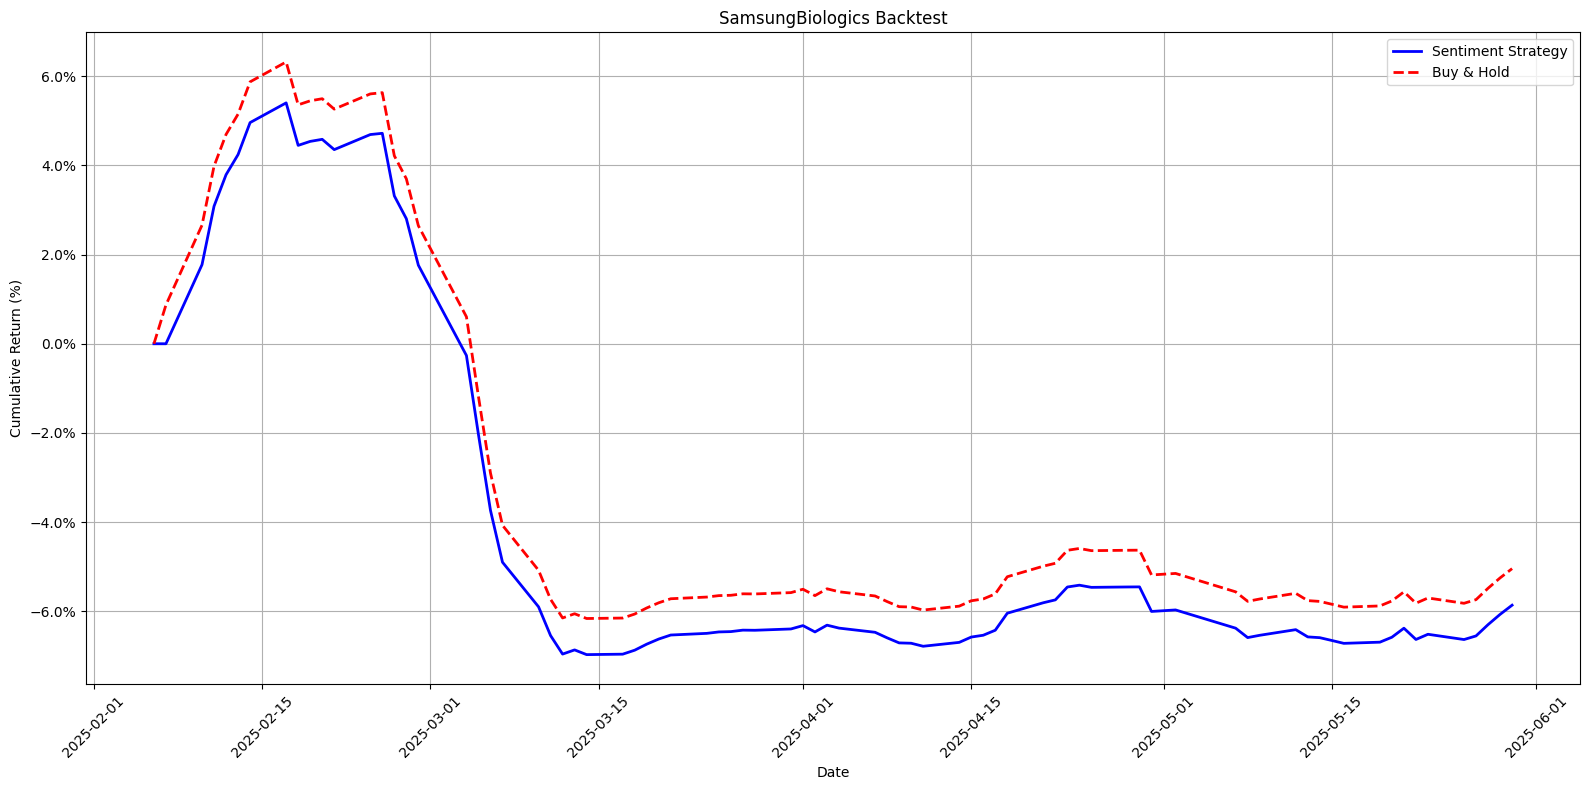

SamsungBiologics 최종 자본: 9,413,863 KRW, 최종 수익률: -5.86%


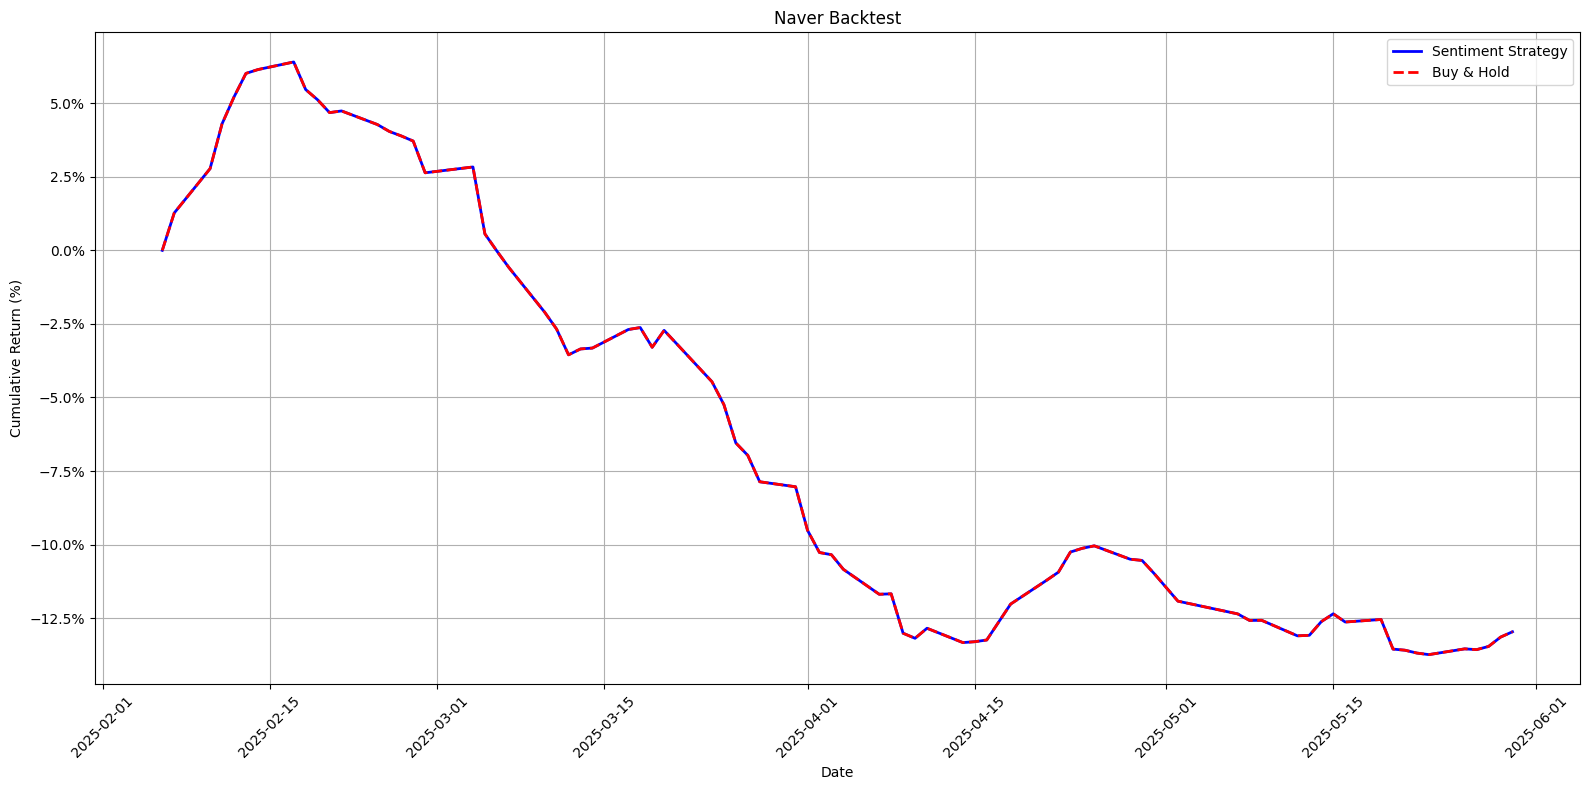

Naver 최종 자본: 8,703,584 KRW, 최종 수익률: -12.96%


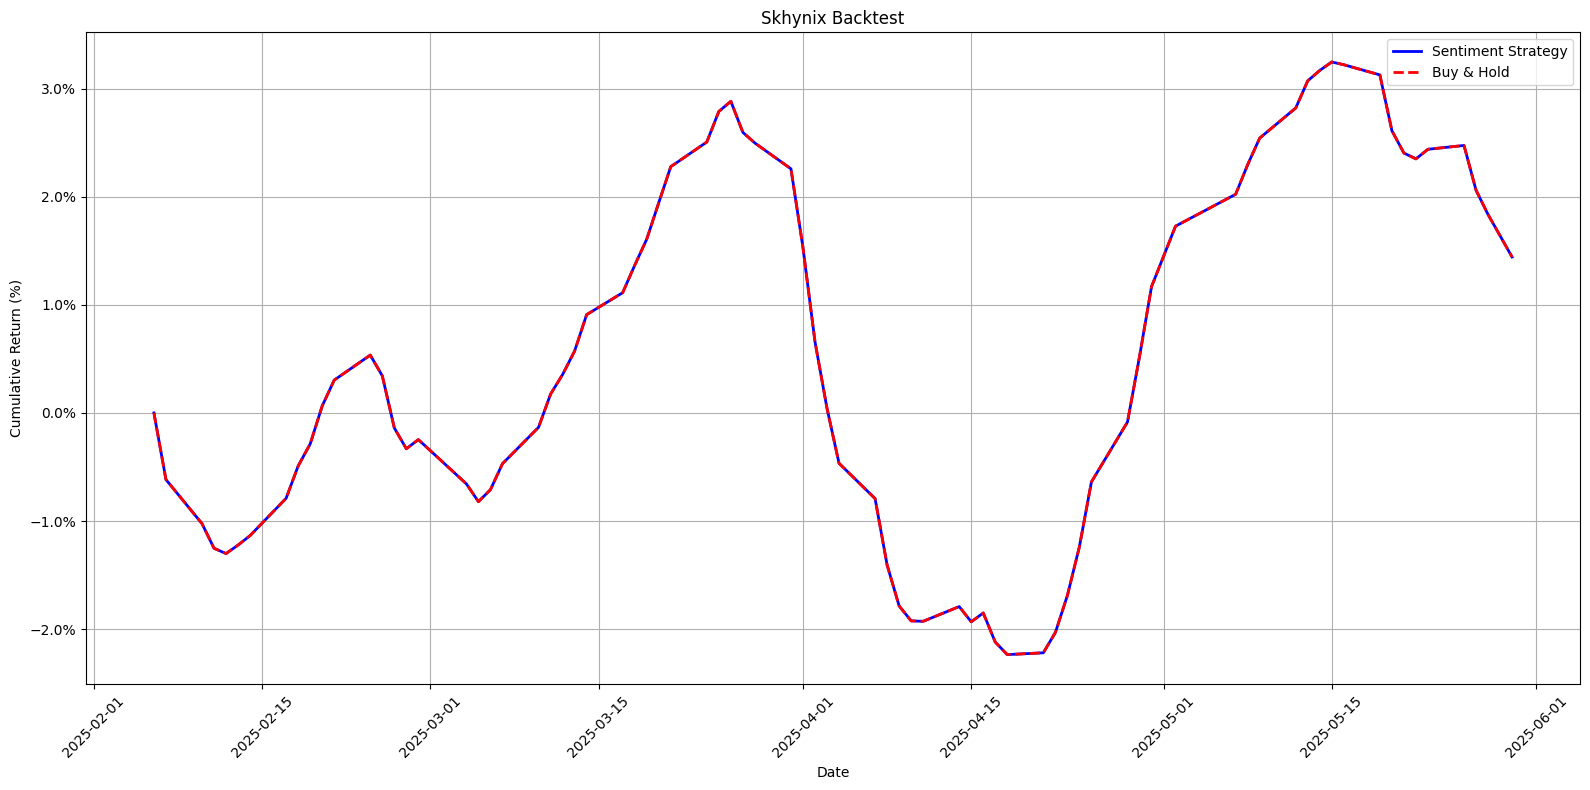

Skhynix 최종 자본: 10,144,226 KRW, 최종 수익률: 1.44%


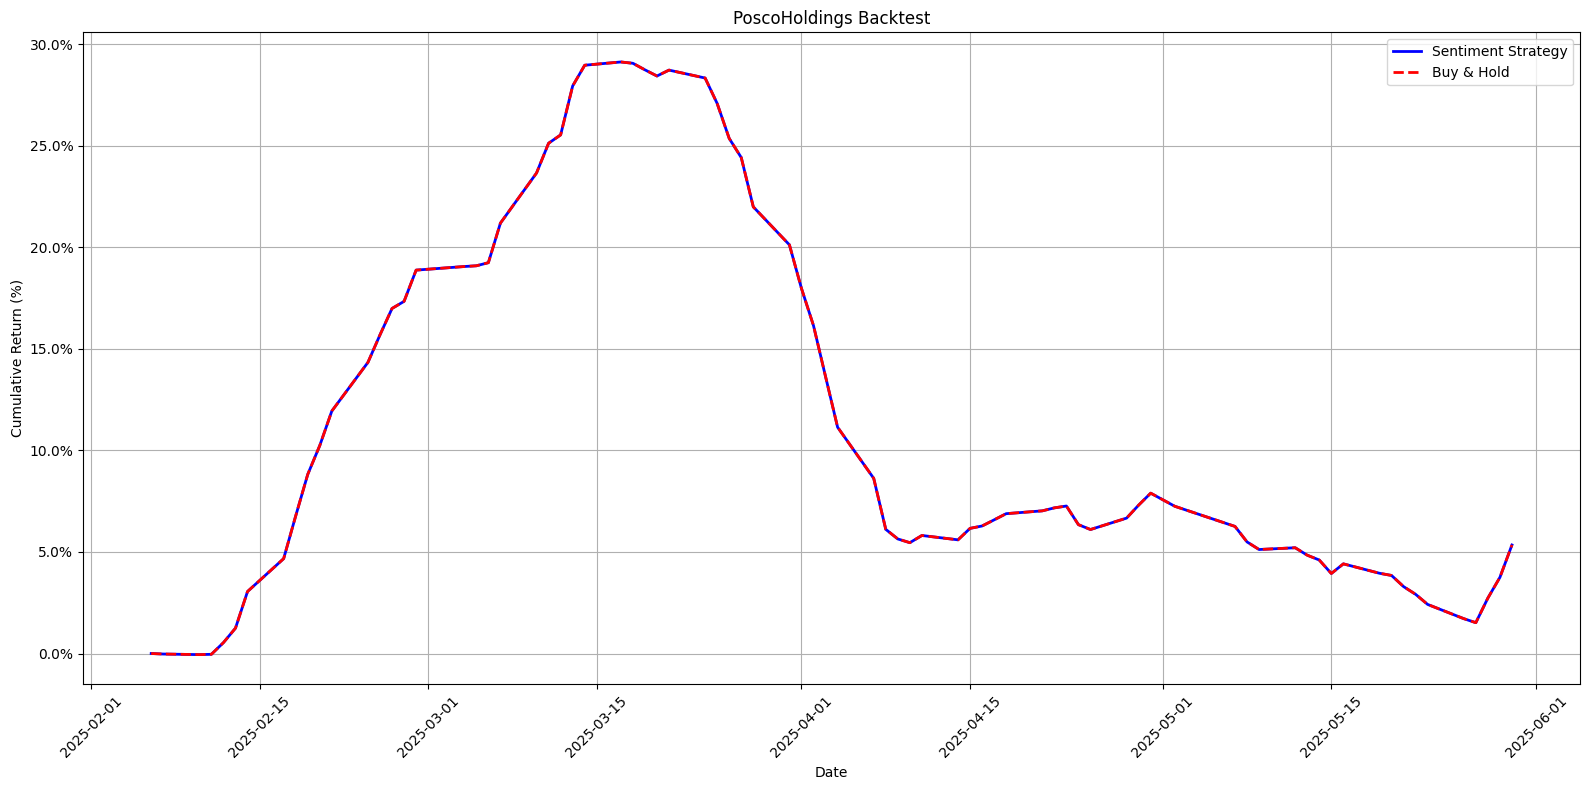

PoscoHoldings 최종 자본: 10,534,538 KRW, 최종 수익률: 5.35%


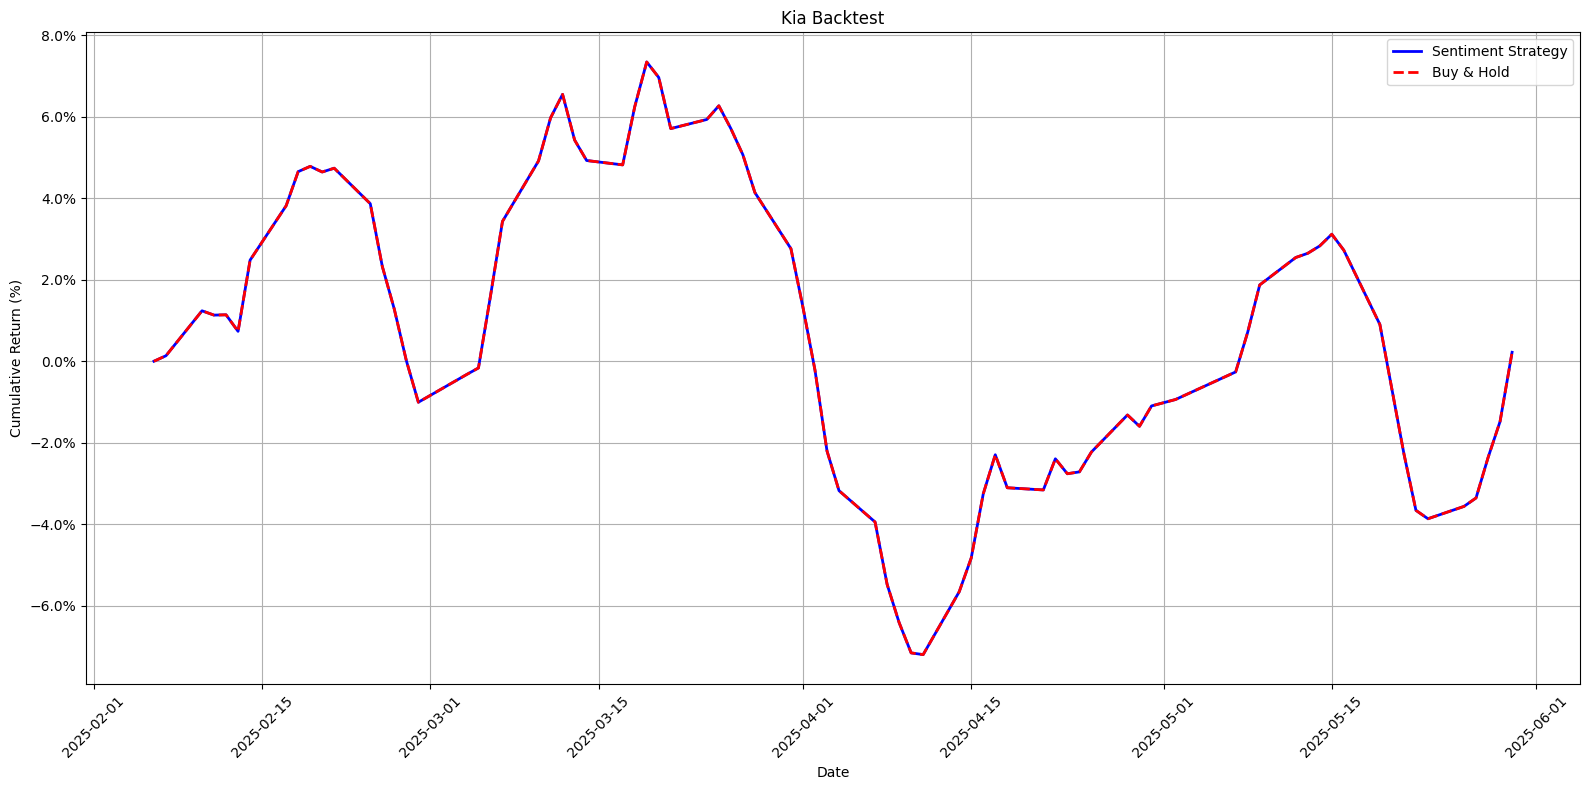

Kia 최종 자본: 10,022,015 KRW, 최종 수익률: 0.22%


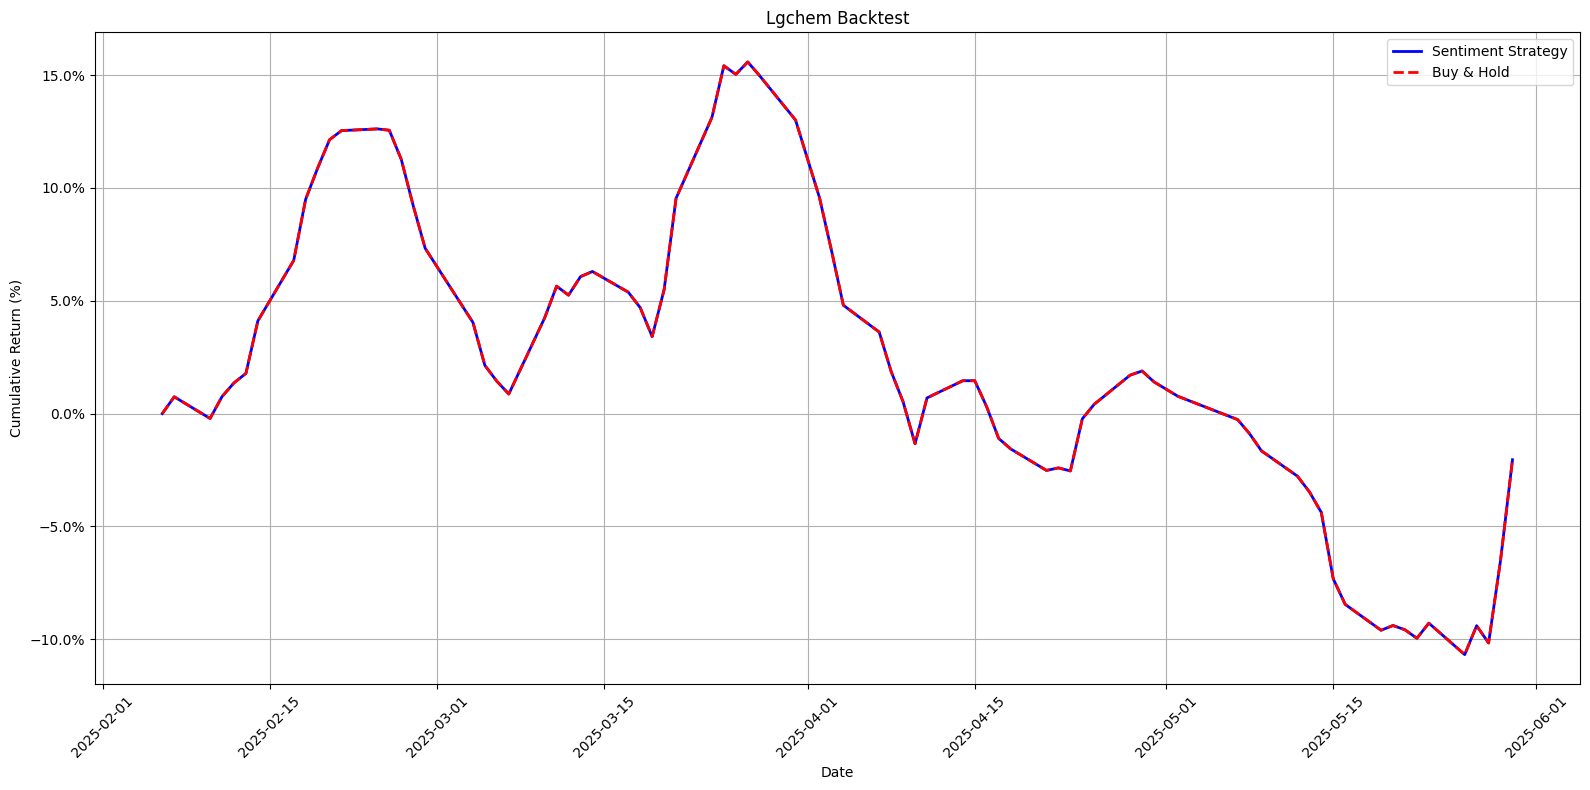

Lgchem 최종 자본: 9,795,629 KRW, 최종 수익률: -2.04%


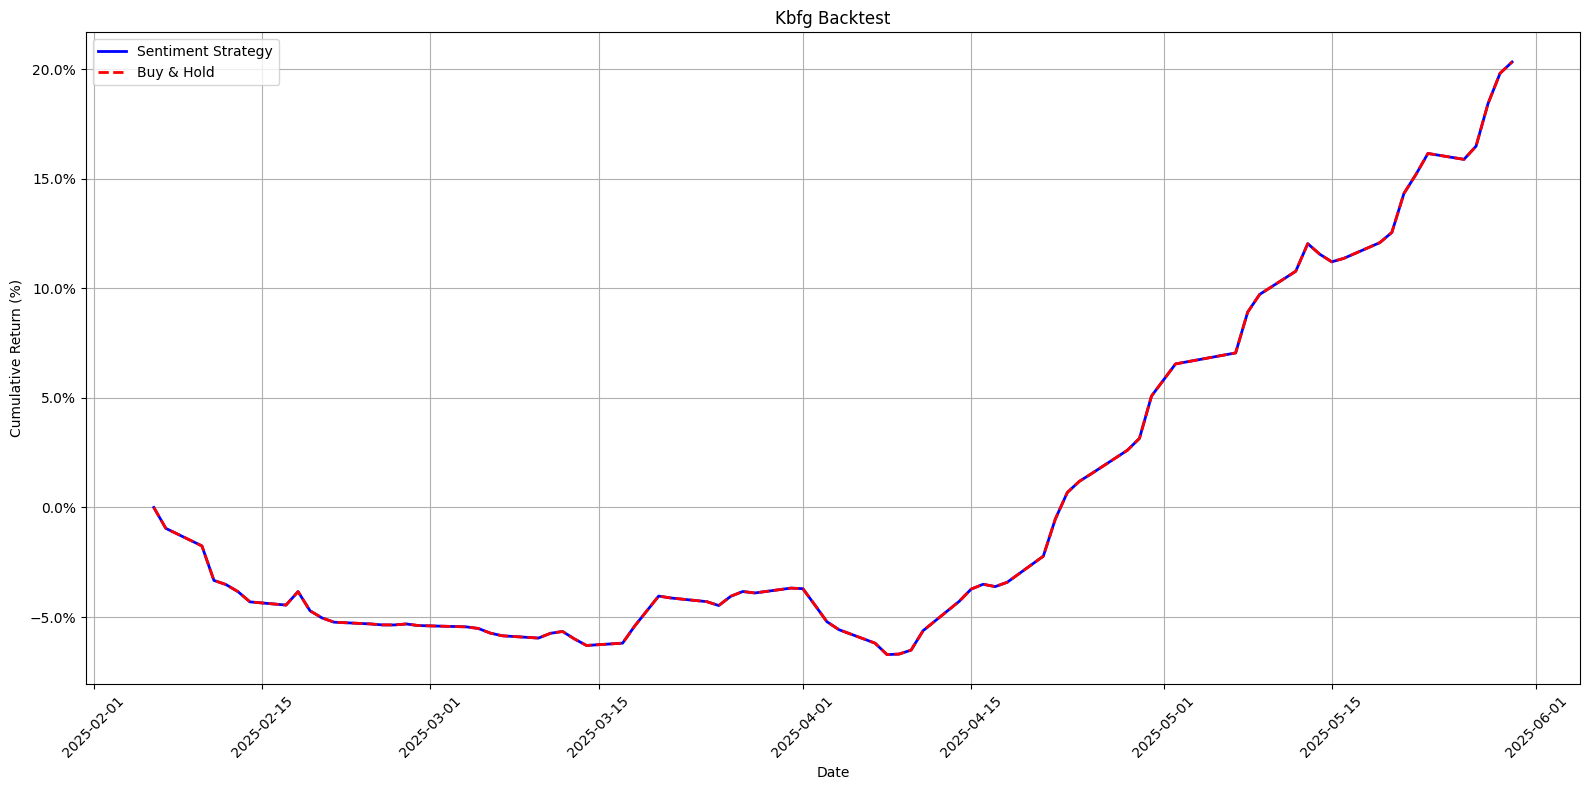

Kbfg 최종 자본: 12,032,360 KRW, 최종 수익률: 20.32%


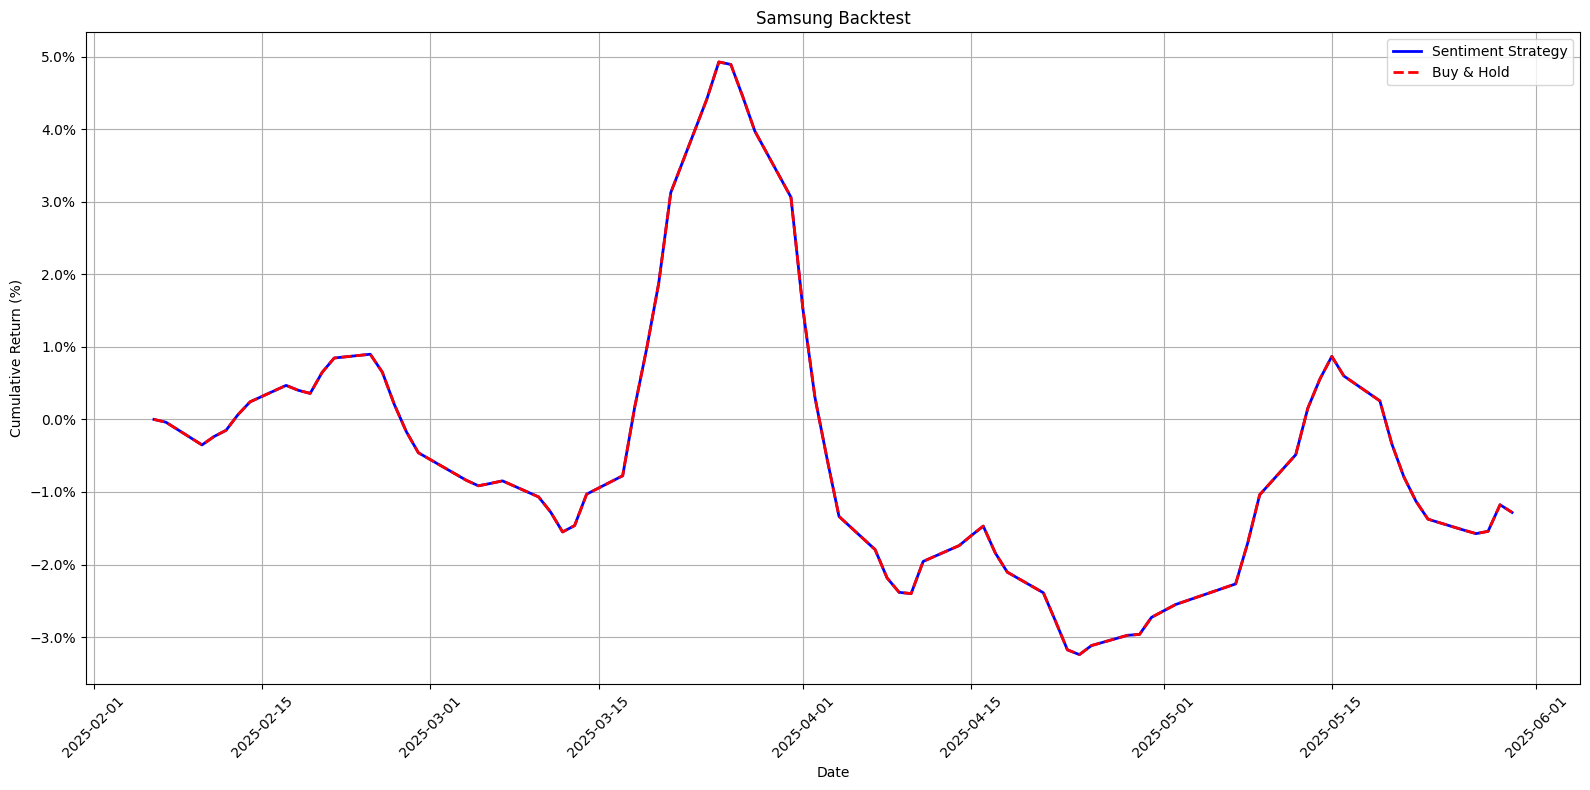

Samsung 최종 자본: 9,871,797 KRW, 최종 수익률: -1.28%


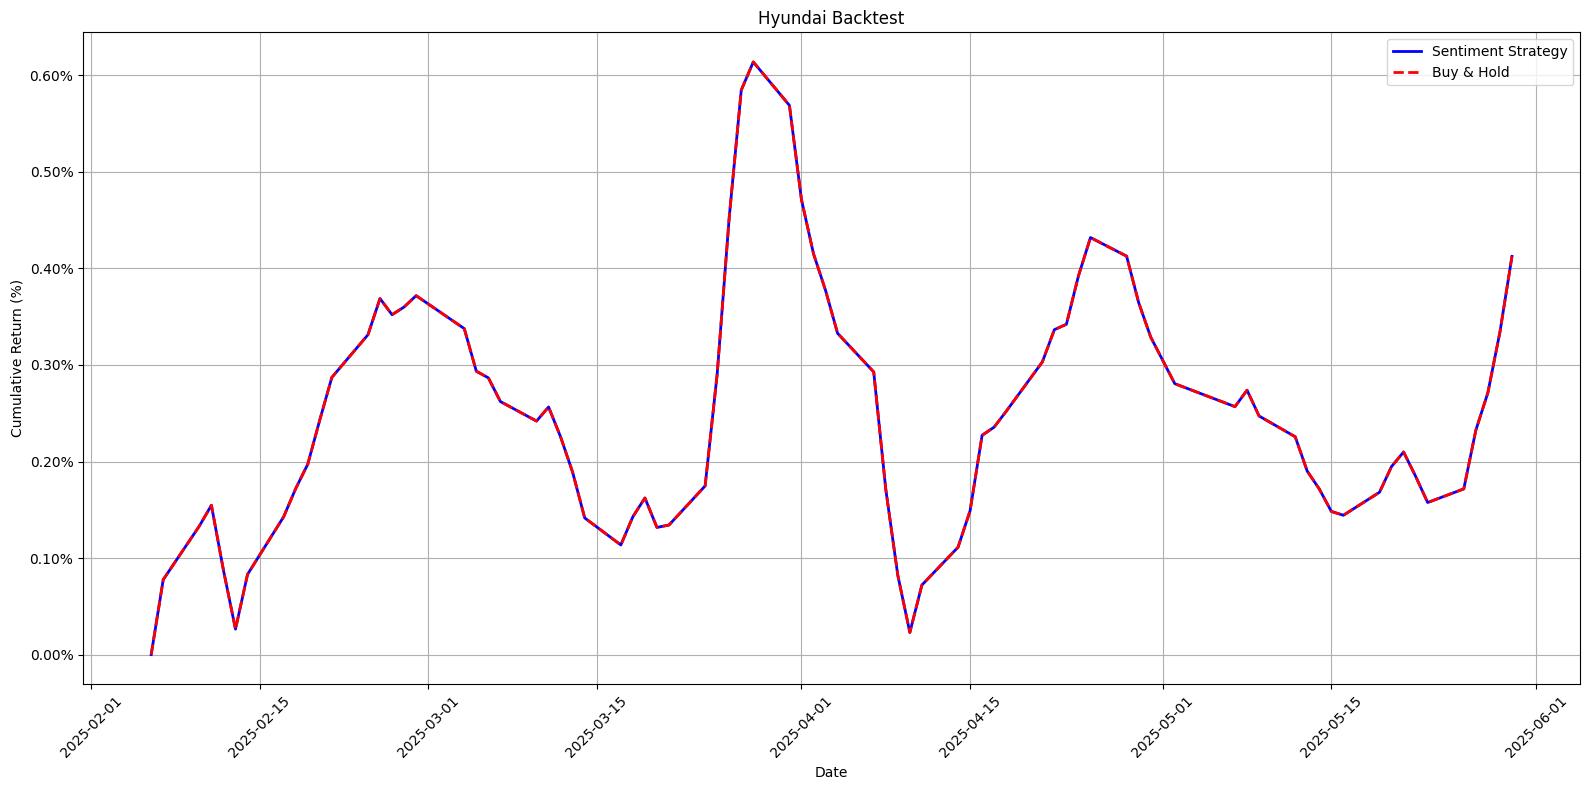

Hyundai 최종 자본: 10,041,244 KRW, 최종 수익률: 0.41%


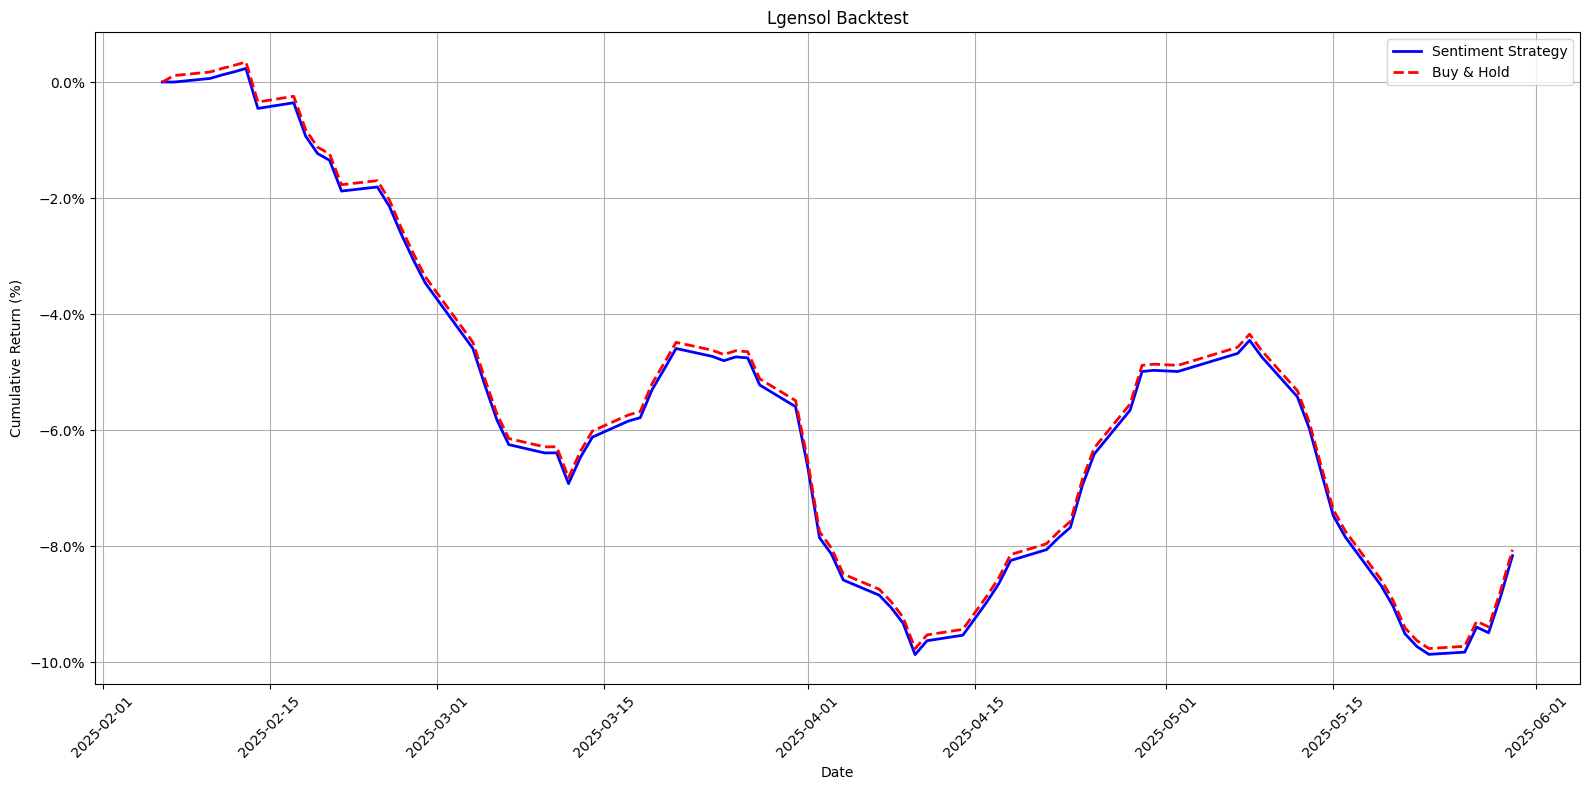

Lgensol 최종 자본: 9,183,860 KRW, 최종 수익률: -8.16%


In [ ]:
initial_capital = 10000000
for company in companies:
    file_path = os.path.join(input_folder, f"result_{company}.csv")
    df = pd.read_csv(file_path)

    if 'emotion' not in df.columns:
        print(f"⚠️ {company} emotion 컬럼 없음, 스킵")
        continue

    df['date'] = pd.to_datetime(df['date'])
    backtest_df = run_backtest(df, initial_capital)
    visualize_backtest(backtest_df, company)
    final_capital = backtest_df['capital'].iloc[-1]
    final_return = backtest_df['return_rate'].iloc[-1]
    print(f"{company} 최종 자본: {final_capital:,.0f} KRW, 최종 수익률: {final_return:.2f}%")